# 01 · YuNet: face detection

**What it is.** YuNet (Wu et al., a lightweight face detector from the OpenCV model zoo, MIT licence), `yunet_s_dynamic.onnx` (232 KB). It finds faces, a confidence score and five landmarks. Everything face-related in FaceCloud (quality checks, person folders, identity gates) starts here.

**How it is scored.** The project has no hand-labelled face benchmark, so this notebook does not claim absolute accuracy. It measures what it honestly can:
1. the **score distribution** of the detector on all photographs in the database;
2. **robustness with a reference**: for each portrait where YuNet finds a face on the clean photo (the reference), the photo is degraded in controlled ways and **recall** = share of faces still found with IoU >= 0.5 to the reference box;
3. speed.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · What the detector produced on the whole library (database)

photographs 300 | with a face 243 | no face 57 | mean confidence 0.880 | share below 0.7: 9.5%


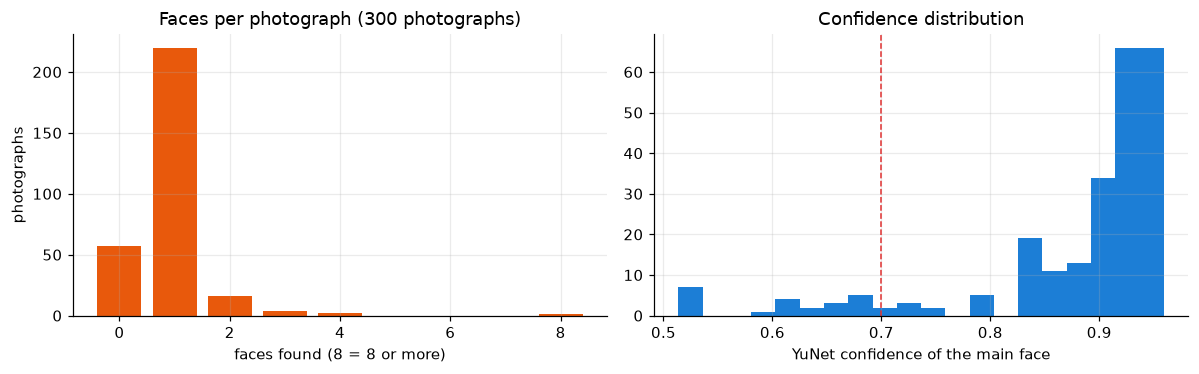

In [2]:
from validation.models import FaceValidationResult
rows_db = list(FaceValidationResult.objects.values_list("face_count", "primary_confidence", "decision"))
counts = np.array([r[0] for r in rows_db]); conf = np.array([r[1] for r in rows_db if r[1] is not None])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(*np.unique(np.minimum(counts, 8), return_counts=True), color=COLORS["model"]); ax[0].set_xlabel("faces found (8 = 8 or more)"); ax[0].set_ylabel("photographs"); ax[0].set_title(f"Faces per photograph ({len(counts)} photographs)")
ax[1].hist(conf, bins=20, color=COLORS["baseline"]); ax[1].axvline(0.7, color=COLORS["bad"], ls="--", lw=1); ax[1].set_xlabel("YuNet confidence of the main face"); ax[1].set_title("Confidence distribution")
fig.tight_layout(); save(fig, "01_yunet_distribution.png")
print(f"photographs {len(counts)} | with a face {int((counts > 0).sum())} | no face {int((counts == 0).sum())} | mean confidence {conf.mean():.3f} | share below 0.7: {(conf < 0.7).mean():.1%}")

## 2 · Robustness with a reference (public portraits, controlled degradations)

[ WARN:0@1.083] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


16 portraits with a confident reference face


degradation  recall  mean_score
-----------  ------  ----------
blur 1       1.00    0.89      
blur 2       1.00    0.88      
blur 4       0.88    0.86      
blur 6       0.69    0.83      
noise 10     0.94    0.86      
noise 25     0.50    0.81      
noise 50     0.00    0.00      
dark 2       0.94    0.88      
dark 4       0.81    0.87      
dark 8       0.62    0.84      
dark 16      0.12    0.70      
jpeg 40      1.00    0.88      
jpeg 15      0.88    0.89      
jpeg 5       0.44    0.86      
small 2      1.00    0.89      
small 4      1.00    0.88      
small 8      0.88    0.87      
detection time per 800 px photograph: 8 ms


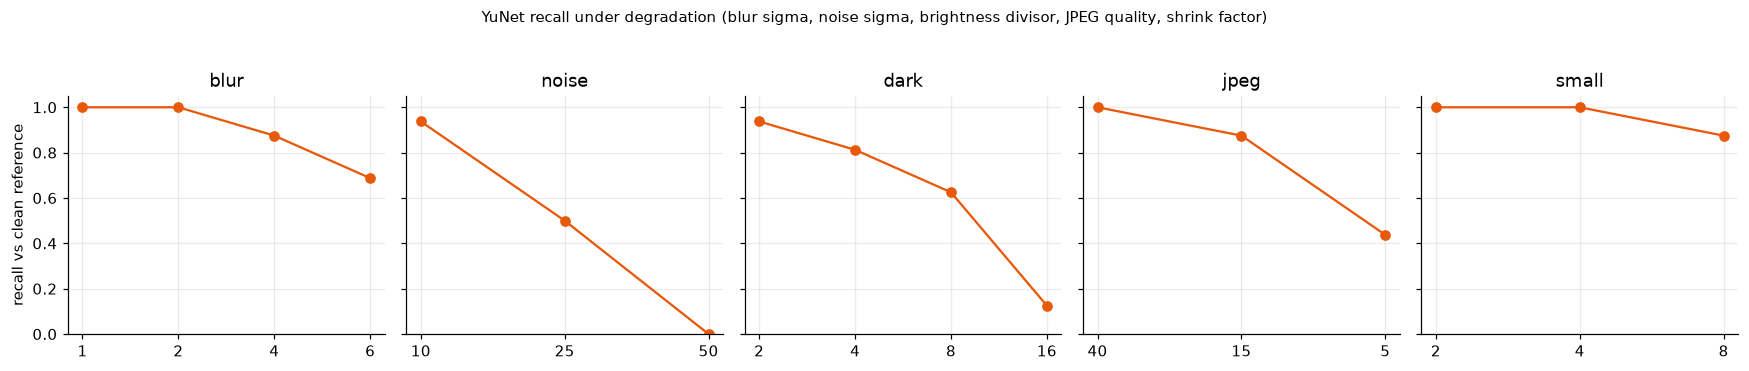

In [3]:
import time
ids = [pk for pk in public_stock_ids()]
refs = []
for pk in ids:
    image = photo(pk, 800); face = largest_face(image)
    if face and face["score"] >= 0.8 and min(face["box"][2:]) >= 60:
        refs.append((pk, image, face))
print(len(refs), "portraits with a confident reference face")
levels = {"blur": [1, 2, 4, 6], "noise": [10, 25, 50], "dark": [2, 4, 8, 16], "jpeg": [40, 15, 5], "small": [2, 4, 8]}
recall = {}
for kind, values in levels.items():
    for v in values:
        hit = total = 0; scores = []
        for pk, image, face in refs:
            found = largest_face(degrade(image, kind, v)); total += 1
            if found and iou(face["box"], found["box"]) >= 0.5: hit += 1; scores.append(found["score"])
        recall[(kind, v)] = (hit / total, float(np.mean(scores)) if scores else 0.0)
fig, ax = plt.subplots(1, len(levels), figsize=(16, 3.2), sharey=True)
for axis, (kind, values) in zip(ax, levels.items()):
    axis.plot(range(len(values)), [recall[(kind, v)][0] for v in values], "o-", color=COLORS["model"]); axis.set_xticks(range(len(values)), [str(v) for v in values]); axis.set_title(kind); axis.set_ylim(0, 1.05)
ax[0].set_ylabel("recall vs clean reference")
fig.suptitle("YuNet recall under degradation (blur sigma, noise sigma, brightness divisor, JPEG quality, shrink factor)", fontsize=10, y=1.04); fig.tight_layout(); save(fig, "01_yunet_robustness.png")
table([{"degradation": f"{k} {v}", "recall": f"{r:.2f}", "mean_score": f"{s:.2f}"} for (k, v), (r, s) in recall.items()])
started = time.perf_counter()
for pk, image, face in refs[:10]: largest_face(image)
ms = (time.perf_counter() - started) / min(10, len(refs)) * 1000; print("detection time per 800 px photograph: %.0f ms" % ms)

{'task': 'face detection', 'metrics': {'photographs': 300, 'with_face_share': 0.81, 'mean_confidence': 0.8796, 'share_conf_below_0.7': 0.0947, 'reference_portraits': 16, 'recall_blur_sigma2': 1.0, 'recall_blur_sigma6': 0.6875, 'recall_noise_sigma25': 0.5, 'recall_dark_x4': 0.8125, 'recall_dark_x16': 0.125, 'recall_jpeg_q15': 0.875, 'recall_small_x4': 1.0, 'ms_per_photo': 7.956}, 'note': 'no labelled benchmark: confidence distribution + recall vs clean reference under degradation'}


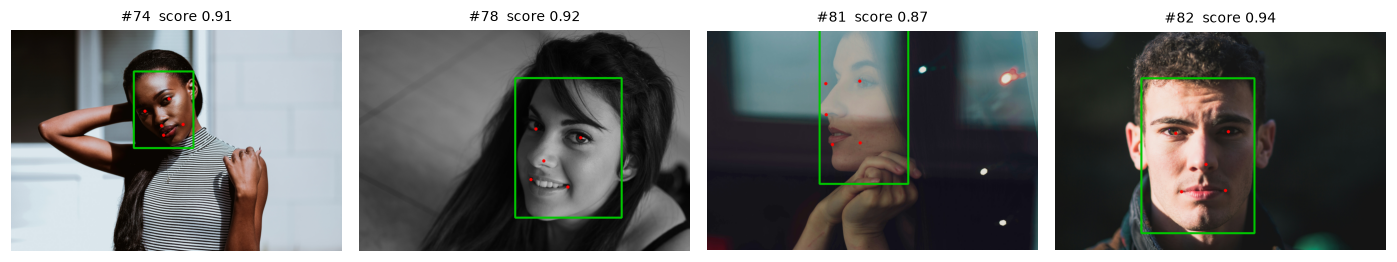

In [4]:
example = refs[0][1].copy()
for pk, image, face in refs[:4]:
    pass
tiles = []
for pk, image, face in refs[:4]:
    t = image.copy(); x, y, w, h = [int(v) for v in face["box"]]; cv2.rectangle(t, (x, y), (x + w, y + h), (0, 200, 0), 3)
    for lx, ly in face["landmarks"]: cv2.circle(t, (int(lx), int(ly)), 4, (0, 0, 255), -1)
    tiles.append(t)
fig = montage(tiles, [f"#{r[0]}  score {r[2]['score']:.2f}" for r in refs[:4]], columns=4, width=3.2); save(fig, "01_yunet_examples.png")
metrics = {"photographs": int(len(counts)), "with_face_share": float((counts > 0).mean()), "mean_confidence": float(conf.mean()), "share_conf_below_0.7": float((conf < 0.7).mean()),
           "reference_portraits": len(refs), "recall_blur_sigma2": recall[("blur", 2)][0], "recall_blur_sigma6": recall[("blur", 6)][0], "recall_noise_sigma25": recall[("noise", 25)][0],
           "recall_dark_x4": recall[("dark", 4)][0], "recall_dark_x16": recall[("dark", 16)][0], "recall_jpeg_q15": recall[("jpeg", 15)][0], "recall_small_x4": recall[("small", 4)][0], "ms_per_photo": float(ms)}
print(scorecard("YuNet", "face detection", metrics, "no labelled benchmark: confidence distribution + recall vs clean reference under degradation"))
save_json("01_yunet.json", metrics)

## Verdict
YuNet is small, fast and keeps finding the reference face through moderate blur, noise, compression and shrinking; recall drops under extreme darkness and heavy shrinking, which is when the application's quality gate already flags the photograph. Detection confidence below ~0.7 contains most borderline detections (the known false-positive source on buildings and screenshots), which is why folder grouping is gated by the quality verdict and not by detection alone.